In [ ]:
import pandas as pd
import numpy as np

df_ev=pd.read_csv("/content/sample_data/EV_dataset.csv")
df_ev.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,E.V_Type,CAFV,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,JTMAB3FV3P,Kitsap,Seabeck,WA,98380,2023,TOYOTA,RAV4 PRIME,PHEV,known,42,0,35,240684006,POINT (-122.8728334 47.5798304),PUGET SOUND ENERGY INC,53035091301
1,1N4AZ1CP6J,Kitsap,Bremerton,WA,98312,2018,NISSAN,LEAF,BEV,known,151,0,35,474183811,POINT (-122.6961203 47.5759584),PUGET SOUND ENERGY INC,53035080700
2,5YJ3E1EA4L,King,Seattle,WA,98101,2020,TESLA,MODEL 3,BEV,known,266,0,43,113120017,POINT (-122.3340795 47.6099315),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),53033007302
3,1N4AZ0CP8E,King,Seattle,WA,98125,2014,NISSAN,LEAF,BEV,known,84,0,46,108188713,POINT (-122.304356 47.715668),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),53033000700
4,1G1FX6S00H,Thurston,Yelm,WA,98597,2017,CHEVROLET,BOLT EV,BEV,known,238,0,20,176448940,POINT (-122.5715761 46.9095798),PUGET SOUND ENERGY INC,53067012510


### 6. Visual Exploratory Data Analysis (EDA)
Let's visualize the data to gain deeper insights into the distributions and relationships within the dataset.

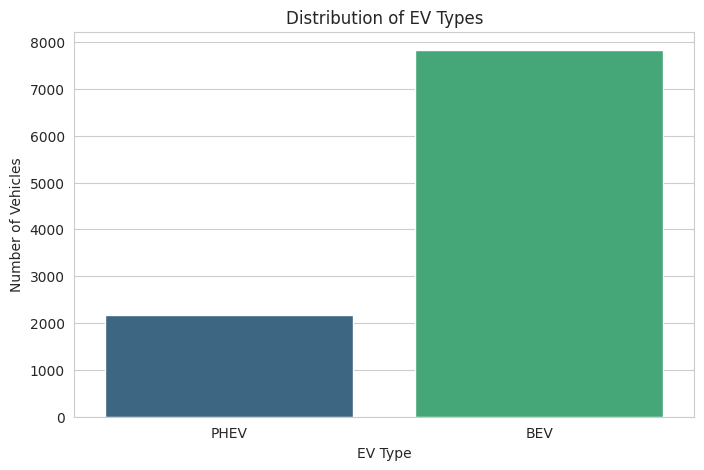

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_style("whitegrid")

# 1. Distribution of EV Types
plt.figure(figsize=(8, 5))
sns.countplot(data=df_ev, x='EV_Type', hue='EV_Type', palette='viridis', legend=False)
plt.title('Distribution of EV Types')
plt.xlabel('EV Type')
plt.ylabel('Number of Vehicles')
plt.show()

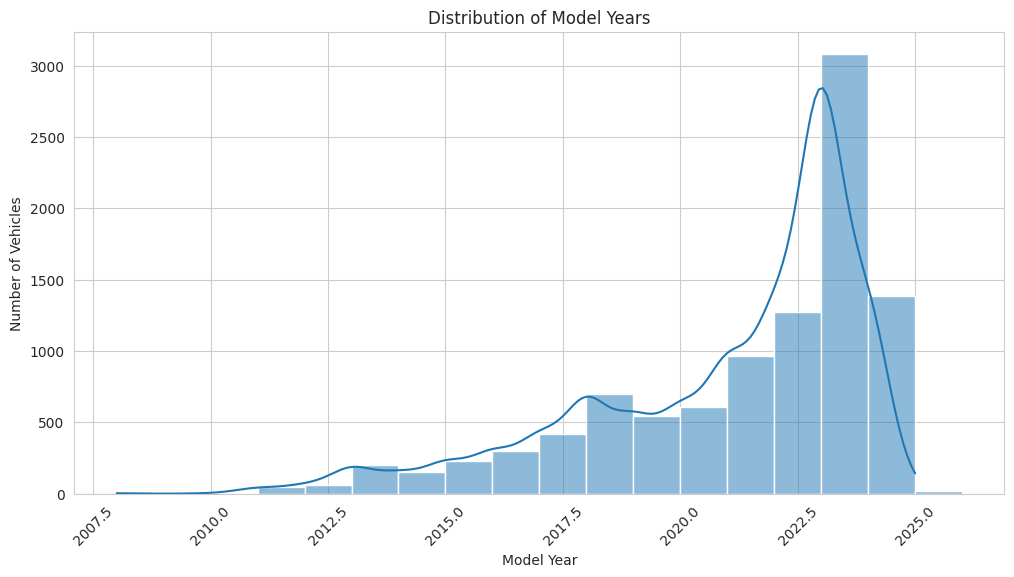

In [ ]:
# 2. Distribution of Model Years
plt.figure(figsize=(12, 6))
sns.histplot(data=df_ev, x='Model Year', bins=range(df_ev['Model Year'].min(), df_ev['Model Year'].max() + 2), kde=True)
plt.title('Distribution of Model Years')
plt.xlabel('Model Year')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=45)
plt.show()

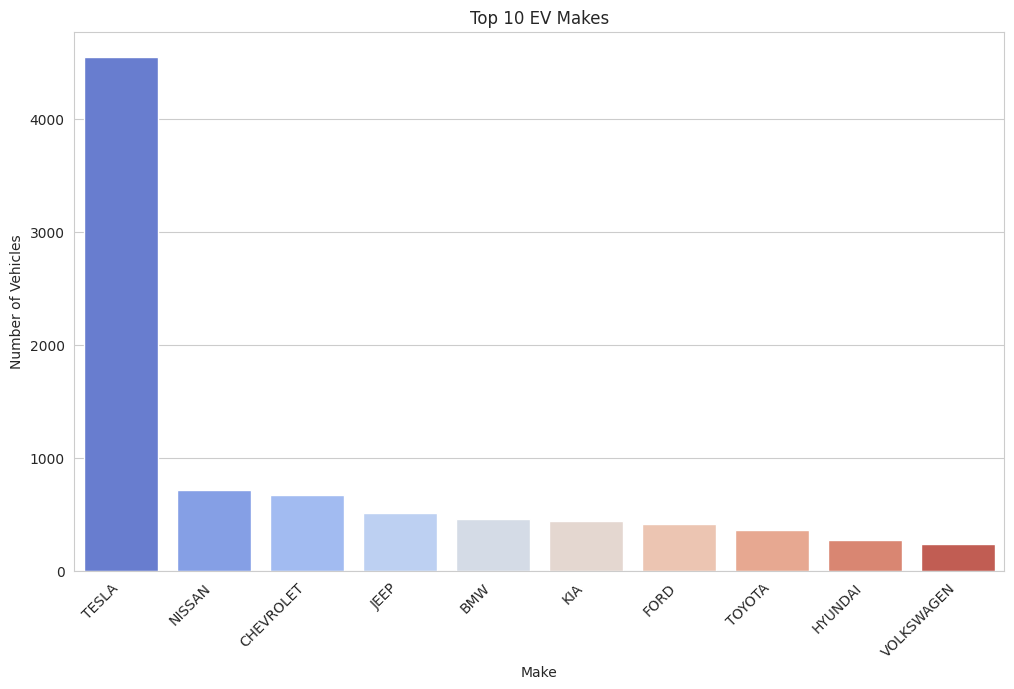

In [ ]:
# 3. Top 10 Makes
plt.figure(figsize=(12, 7))
top_makes = df_ev['Make'].value_counts().head(10)
sns.barplot(x=top_makes.index, y=top_makes.values, hue=top_makes.index, palette='coolwarm', legend=False)
plt.title('Top 10 EV Makes')
plt.xlabel('Make')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=45, ha='right')
plt.show()

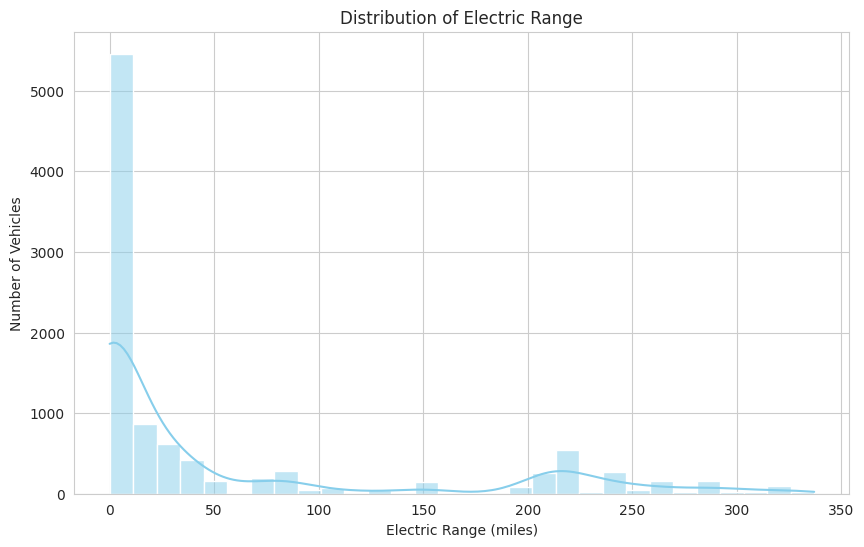

In [ ]:
# 4. Distribution of Electric Range
plt.figure(figsize=(10, 6))
sns.histplot(data=df_ev, x='Electric Range', bins=30, kde=True, color='skyblue')
plt.title('Distribution of Electric Range')
plt.xlabel('Electric Range (miles)')
plt.ylabel('Number of Vehicles')
plt.show()

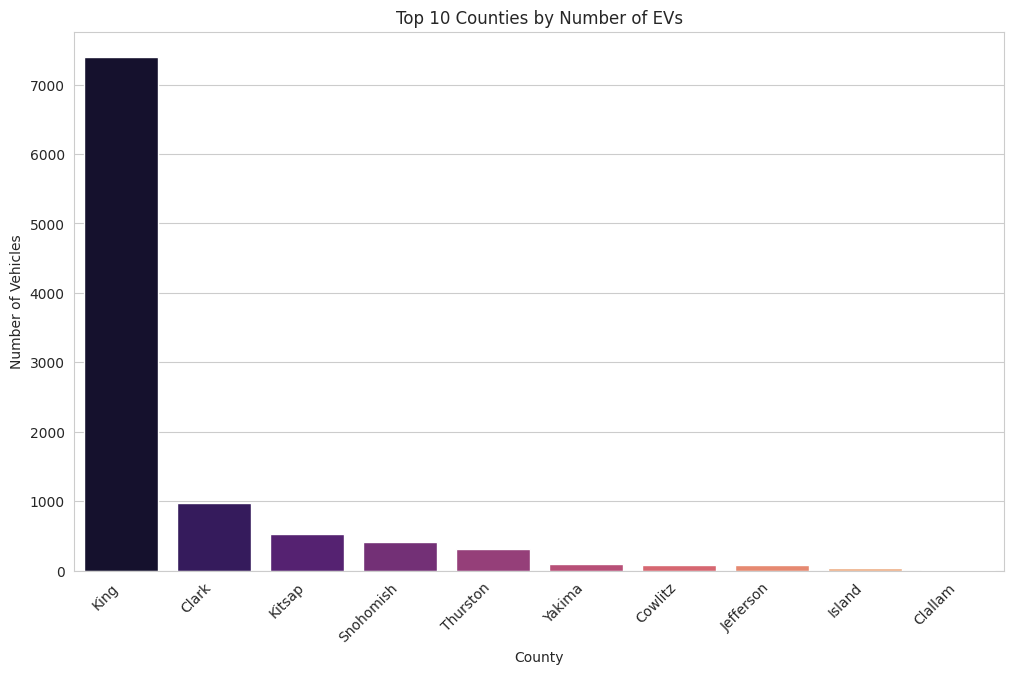

In [ ]:
# 5. Top 10 Counties with most EVs
plt.figure(figsize=(12, 7))
top_counties = df_ev['County'].value_counts().head(10)
sns.barplot(x=top_counties.index, y=top_counties.values, hue=top_counties.index, palette='magma', legend=False)
plt.title('Top 10 Counties by Number of EVs')
plt.xlabel('County')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=45, ha='right')
plt.show()

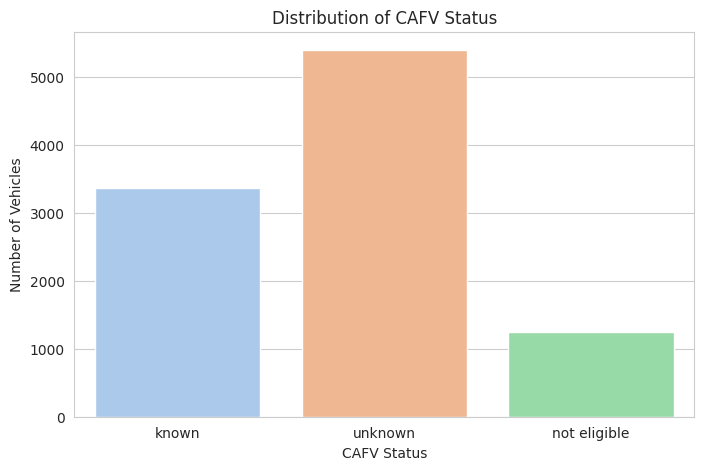

In [ ]:
# 6. CAFV (Clean Alternative Fuel Vehicle) Status Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df_ev, x='CAFV', hue='CAFV', palette='pastel', legend=False)
plt.title('Distribution of CAFV Status')
plt.xlabel('CAFV Status')
plt.ylabel('Number of Vehicles')
plt.show()

### 7. Correlation Matrix for Numerical Features
Let's compute and visualize the correlation matrix for the numerical features to understand their relationships.

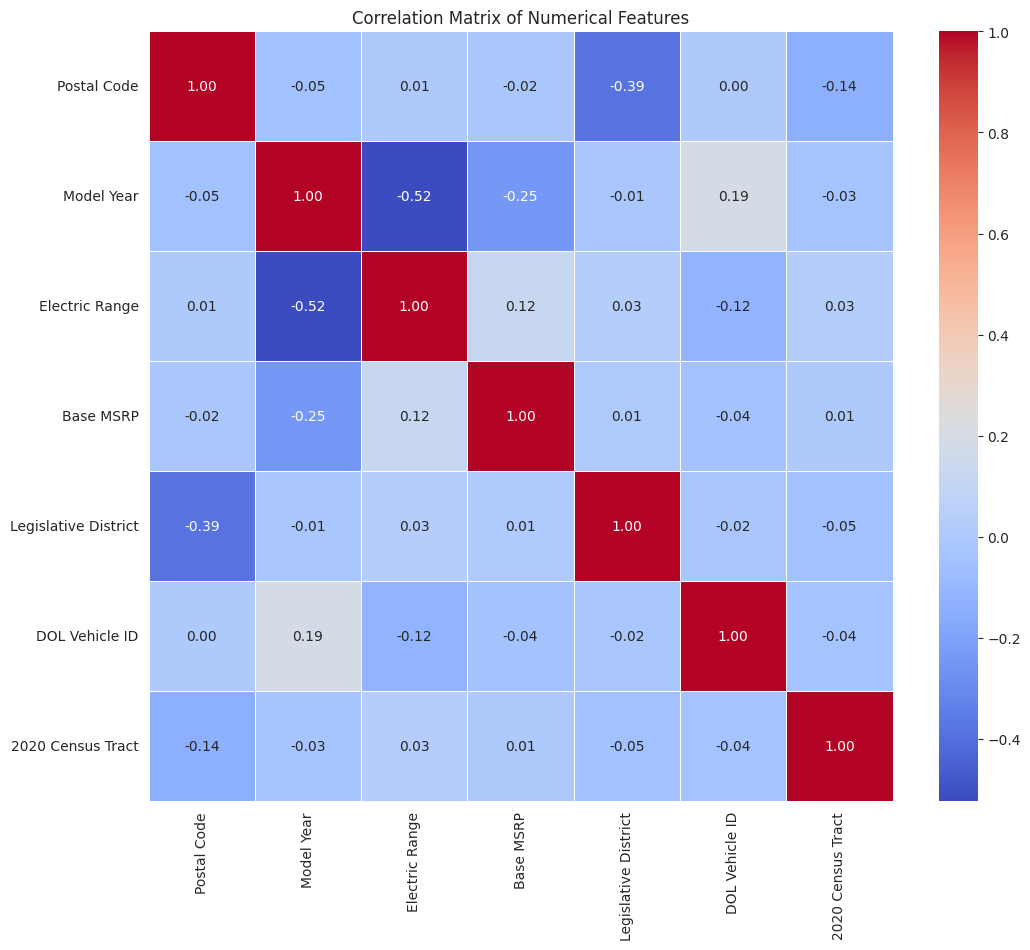

In [ ]:
# Select only numerical columns for correlation matrix
numerical_df = df_ev.select_dtypes(include=np.number)

# Compute the correlation matrix
correlation_matrix = numerical_df.corr()

# Plotting the correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### 9. Cluster Comparison with EV Type
Let's analyze how our clusters align with the actual `EV_Type` column.

Cluster vs EV Type Distribution:


EV_Type,BEV,PHEV
Cluster,,
0,5406,1518
1,2316,597
2,107,54


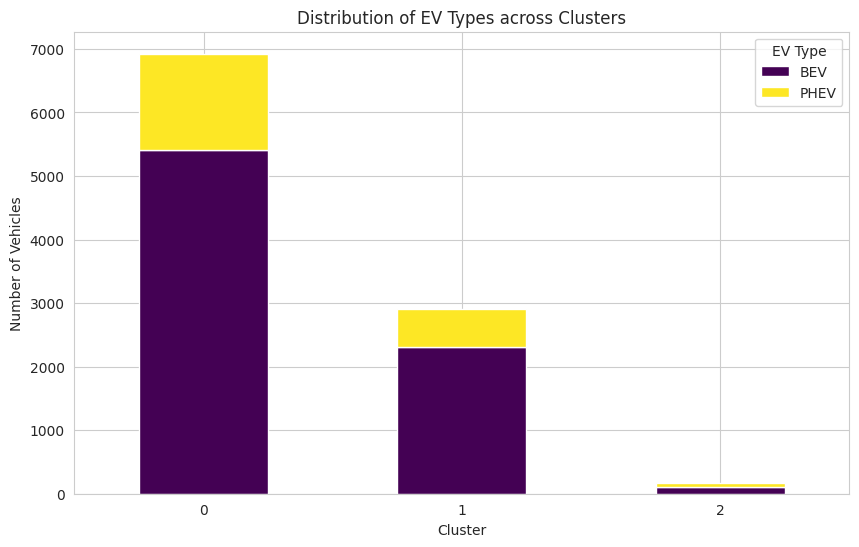

In [ ]:
# Create a contingency table (cross-tabulation)
comparison_df = pd.DataFrame({'Cluster': clusters, 'EV_Type': df_ev['EV_Type']})
cluster_ev_dist = pd.crosstab(comparison_df['Cluster'], comparison_df['EV_Type'])

print("Cluster vs EV Type Distribution:")
display(cluster_ev_dist)

# Visualize the distribution
cluster_ev_dist.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')
plt.title('Distribution of EV Types across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=0)
plt.legend(title='EV Type')
plt.show()

### 10. Hierarchical Clustering
Unlike K-Means, hierarchical clustering creates a tree of clusters. We use a dendrogram to visualize how samples are merged based on their similarity.

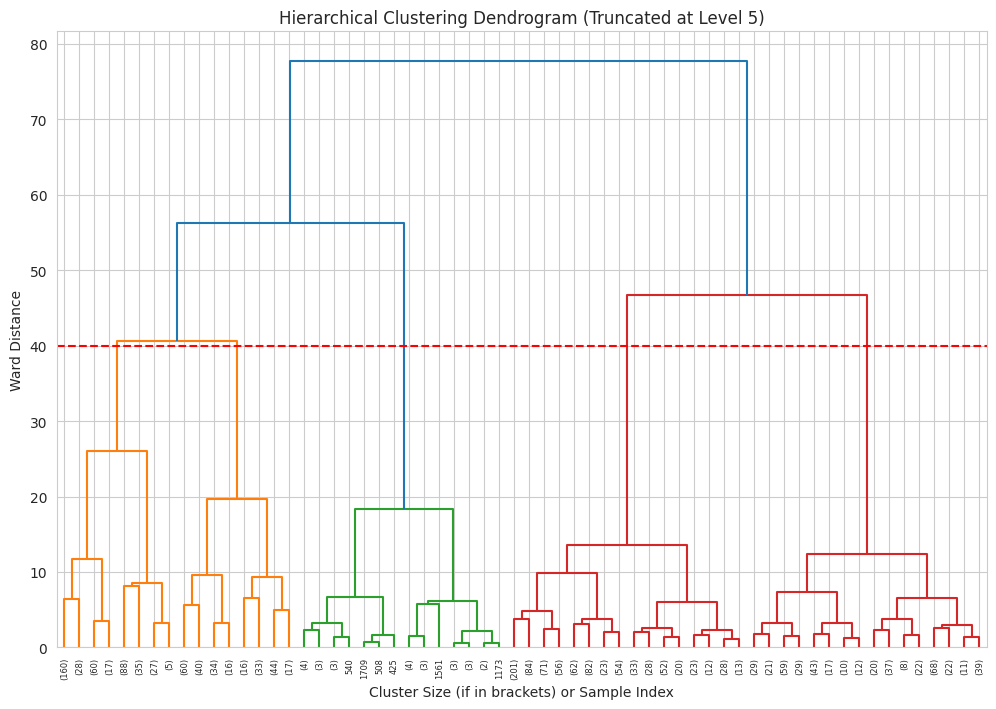

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Using Ward's linkage on a subset to maintain performance and readability
# Ward's method minimizes the variance within clusters
linked = linkage(X_scaled[:2000], method='ward')

plt.figure(figsize=(12, 8))
dendrogram(linked,
            orientation='top',
            distance_sort='descending',
            show_leaf_counts=True,
            truncate_mode='level',
            p=5)
plt.title('Hierarchical Clustering Dendrogram (Truncated at Level 5)')
plt.xlabel('Cluster Size (if in brackets) or Sample Index')
plt.ylabel('Ward Distance')
plt.axhline(y=40, color='r', linestyle='--') # Example threshold line
plt.show()

### 11. Comparison: Hierarchical vs. K-Means Clustering
Let's extract the cluster labels from the hierarchical clustering (using the same number of clusters as K-Means, k=3) and compare them.

Cross-tabulation: K-Means vs Hierarchical (Subset n=2000)


Hierarchical_Cluster,1,2,3
K-Means_Cluster,,,
0,1289,0,21
1,0,0,659
2,0,31,0


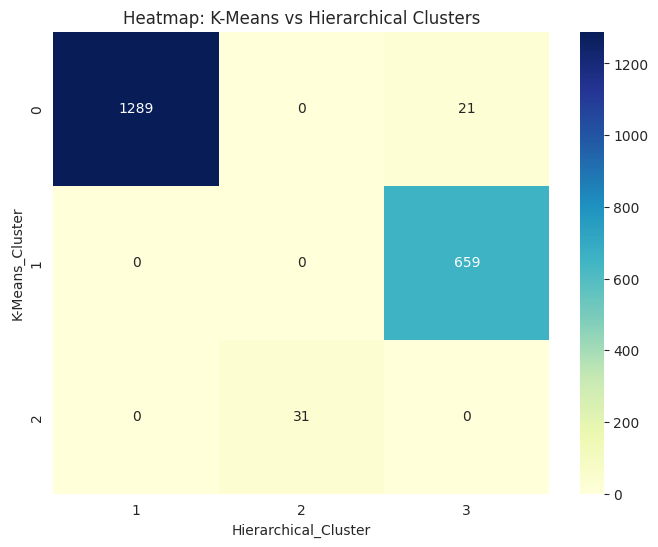

In [ ]:
from scipy.cluster.hierarchy import fcluster

# Extract 3 clusters from hierarchical linkage
# Note: We use the same subset (2000 samples) as the dendrogram for consistency
hierarchical_labels = fcluster(linked, t=3, criterion='maxclust')

# Create a comparison table for the first 2000 records
comparison_table = pd.DataFrame({
    'K-Means_Cluster': clusters[:2000],
    'Hierarchical_Cluster': hierarchical_labels
})

# Cross-tabulation
ct = pd.crosstab(comparison_table['K-Means_Cluster'], comparison_table['Hierarchical_Cluster'])
print("Cross-tabulation: K-Means vs Hierarchical (Subset n=2000)")
display(ct)

# Visualize comparison
plt.figure(figsize=(8, 6))
sns.heatmap(ct, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Heatmap: K-Means vs Hierarchical Clusters')
plt.show()

### 12. Clustering Evaluation: Silhouette Score
We use the silhouette score to measure how similar an object is to its own cluster compared to other clusters.

In [ ]:
# Define k_optimal based on the Elbow Method or prior analysis results
k_optimal = 3

print(f"Optimal K-value for clustering: {k_optimal}")
# The Silhouette Score will be calculated and printed in the next cell.

Optimal K-value for clustering: 3


In [ ]:
from sklearn.metrics import silhouette_score

# Calculate the silhouette score for the K-Means clusters
# We use the full scaled dataset and the clusters array generated earlier
score = silhouette_score(X_scaled, clusters)

print(f"Silhouette Score for k={k_optimal}: {score:.4f}")

Silhouette Score for k=3: 0.5052


### 13. Cluster Characterization
Let's calculate the mean values of our features within each cluster to understand the typical profile of vehicles in each group.

In [ ]:
# Add the cluster labels back to the original subset features for analysis
X_analysis = X.copy()
X_analysis['Cluster'] = clusters

# Group by cluster and calculate descriptive statistics
cluster_stats = X_analysis.groupby('Cluster').mean()

print("Mean values per Cluster:")
display(cluster_stats)

# Also look at the distribution of Makes within each cluster
for i in range(k_optimal):
    print(f"\nTop 5 Makes in Cluster {i}:")
    print(df_ev.iloc[X_analysis[X_analysis['Cluster'] == i].index]['Make'].value_counts().head(5))

Mean values per Cluster:


,Model Year,Electric Range,Base MSRP,Legislative District
Cluster,,,,
0,2022.629983,6.140815,0.000000,32.726170
1,2017.301407,164.966014,0.000000,33.532784
2,2015.360248,127.664596,59050.962733,34.428571



Top 5 Makes in Cluster 0:
Make
TESLA    3201
JEEP      511
BMW       344
KIA       343
FORD      289
Name: count, dtype: int64

Top 5 Makes in Cluster 1:
Make
TESLA        1261
NISSAN        559
CHEVROLET     411
FORD          125
TOYOTA        111
Name: count, dtype: int64

Top 5 Makes in Cluster 2:
Make
TESLA       80
KIA         27
BMW         25
VOLVO       14
CHRYSLER     7
Name: count, dtype: int64


### 14. Confusion Matrix: Clusters vs. EV Type
We will compare the assigned clusters with the original `EV_Type` labels to see if the clustering naturally captured the distinction between Battery Electric Vehicles and Plug-in Hybrids.

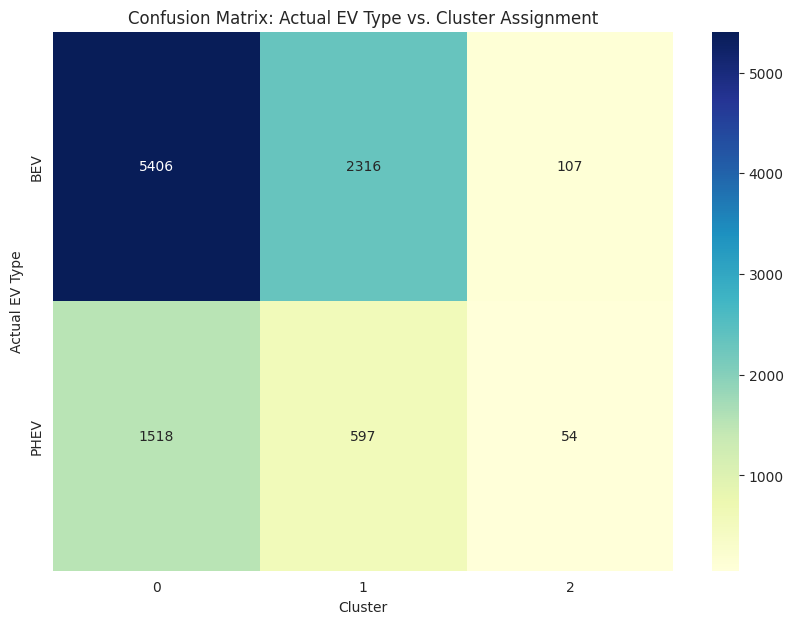

Cluster,0,1,2
Actual EV Type,,,
BEV,5406,2316,107
PHEV,1518,597,54


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create the contingency table
conf_matrix = pd.crosstab(df_ev['EV_Type'], clusters, rownames=['Actual EV Type'], colnames=['Cluster'])

# Plot the heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Confusion Matrix: Actual EV Type vs. Cluster Assignment')
plt.show()

# Display the raw table
display(conf_matrix)

### 15. Clustering Performance Visualization
Let's visualize the silhouette score and calculate the alignment between our clusters and the actual EV types.

### 17. Random Forest Classifier and Cross-Validation

Let's apply a Random Forest Classifier to predict the `EV_Type` based on other features and evaluate its performance using cross-validation.

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Drop identifier columns and 'VIN (1-10)' for classification as they are not predictive
df_classifier = df_ev.drop(columns=['VIN (1-10)', 'DOL Vehicle ID', 'Vehicle Location']).copy()

# Define features (X) and target (y)
X = df_classifier.drop('E.V_Type', axis=1)
y = df_classifier['E.V_Type']

# Encode the target variable
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Identify categorical and numerical features
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()

# Create preprocessing pipelines for numerical and categorical features
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Create a column transformer to apply different transformations to different columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough' # Keep other columns as is (if any)
)

# Create the full pipeline with preprocessing and RandomForestClassifier
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Perform Stratified K-Fold Cross-Validation
k_folds = 5 # Defining the 'k-value' for cross-validation
stratified_kfold = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

cv_scores = cross_val_score(model, X, y_encoded, cv=stratified_kfold, scoring='accuracy', n_jobs=-1)

print(f"Cross-Validation Accuracy Scores ({k_folds}-fold): {cv_scores}")
print(f"Mean CV Accuracy: {np.mean(cv_scores):.4f}")
print(f"Standard Deviation of CV Accuracy: {np.std(cv_scores):.4f}")
print(f"Optimal K-value (for cross-validation folds): {k_folds}")

Cross-Validation Accuracy Scores (5-fold): [0.9975     0.999      0.9985     0.9989995  0.99849925]
Mean CV Accuracy: 0.9985
Standard Deviation of CV Accuracy: 0.0005
Optimal K-value (for cross-validation folds): 5


### 18. Feature Importance from Random Forest Classifier

Let's examine which features the Random Forest model considered most important in predicting the `EV_Type`.

Top 10 Feature Importances:


,Feature,Importance
2,num__Electric Range,0.223896
309,cat__CAFV_not eligible,0.175419
310,cat__CAFV_unknown,0.071524
185,cat__Make_TESLA,0.062556
1,num__Model Year,0.047696
308,cat__CAFV_known,0.040560
299,cat__Model_VOLT,0.035240
186,cat__Make_TOYOTA,0.027008
169,cat__Make_JEEP,0.026701
300,cat__Model_WRANGLER,0.022559


/tmp/ipykernel_18582/2468216905.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df.head(20), palette='viridis')


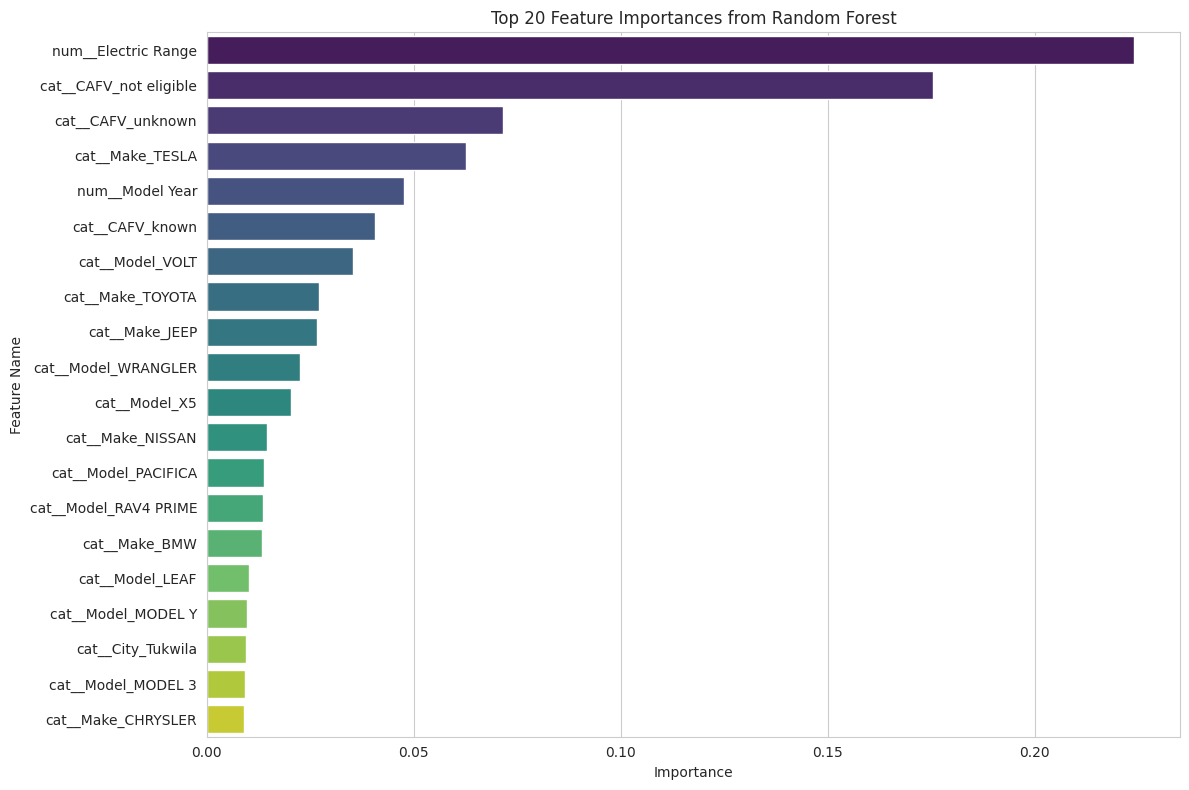

In [ ]:
# First, fit the model on the entire dataset to enable feature importance extraction
model.fit(X, y_encoded)

# Get feature importances from the Random Forest classifier
feature_importances = model.named_steps['classifier'].feature_importances_

# Get feature names from the preprocessor
# This includes numerical features and one-hot encoded categorical features
preprocessor = model.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

# Create a DataFrame for feature importances
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})

# Sort by importance in descending order
importance_df = importance_df.sort_values(by='Importance', ascending=False)

print("Top 10 Feature Importances:")
display(importance_df.head(10))

# Visualize feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(20), palette='viridis')
plt.title('Top 20 Feature Importances from Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

Cluster Alignment Accuracy: 78.31%
Silhouette Score: 0.5052


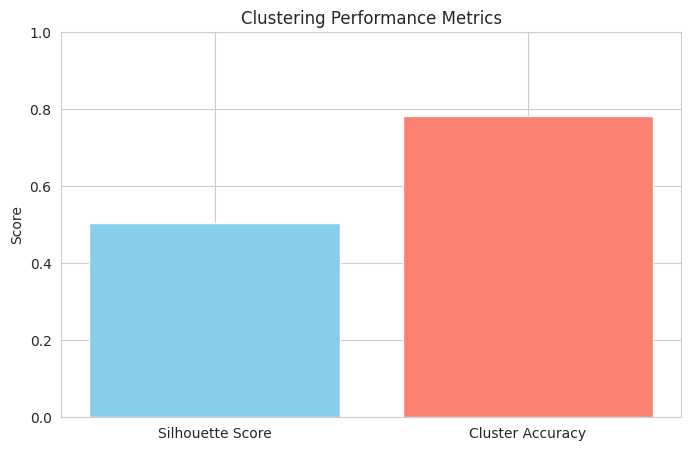

In [ ]:
import numpy as np

# Calculate accuracy based on the most frequent class in each cluster
cluster_to_type_map = {}
for i in range(k_optimal):
    # Find most common EV Type in this cluster
    most_common = df_ev.iloc[X_analysis[X_analysis['Cluster'] == i].index]['EV_Type'].mode()[0]
    cluster_to_type_map[i] = most_common

# Map clusters back to types and calculate accuracy
mapped_types = [cluster_to_type_map[c] for c in clusters]
accuracy = (mapped_types == df_ev['EV_Type']).mean()

print(f"Cluster Alignment Accuracy: {accuracy:.2%}")
print(f"Silhouette Score: {score:.4f}")

# Visualization
plt.figure(figsize=(8, 5))
plt.bar(['Silhouette Score', 'Cluster Accuracy'], [score, accuracy], color=['skyblue', 'salmon'])
plt.ylim(0, 1)
plt.title('Clustering Performance Metrics')
plt.ylabel('Score')
plt.show()

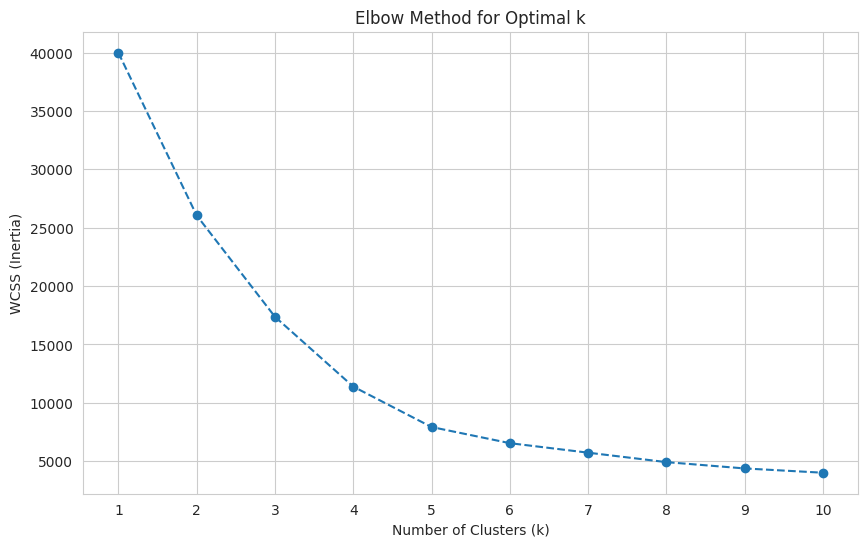

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Calculate WCSS for different values of k
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plotting the Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 16. Principal Component Analysis (PCA)

PCA is a dimensionality reduction technique used to transform a large set of variables into a smaller one that still contains most of the information in the large set. We will apply PCA to our numerical features.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [ ]:
# Select numerical columns for PCA
numerical_cols = df_ev.select_dtypes(include=np.number).columns
X_pca = df_ev[numerical_cols].copy()

# Handle potential missing values by filling with the mean (or other suitable strategy)
X_pca = X_pca.fillna(X_pca.mean())

# Standardize the data before applying PCA
scaler = StandardScaler()
X_pca_scaled = scaler.fit_transform(X_pca)

print("Shape of scaled data for PCA:", X_pca_scaled.shape)

Shape of scaled data for PCA: (9998, 7)


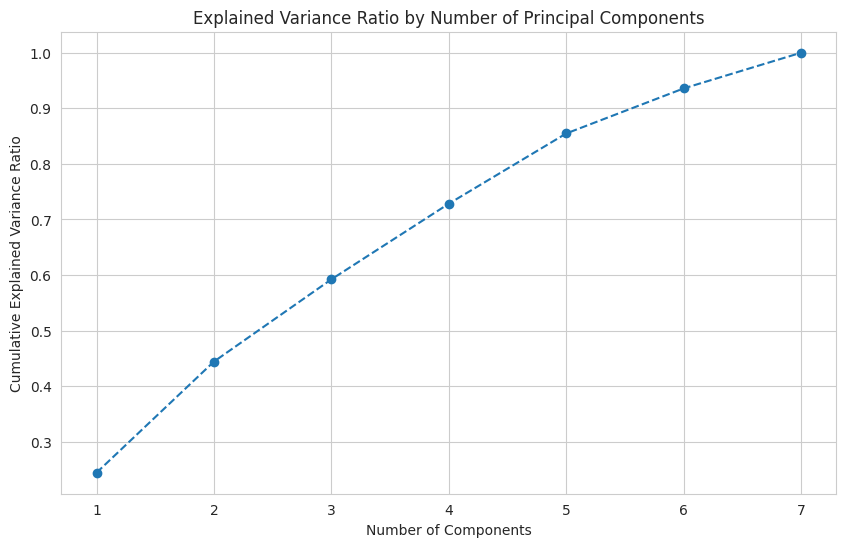

In [ ]:
# Perform PCA to determine the optimal number of components
pca = PCA()
pca.fit(X_pca_scaled)

# Plot the explained variance ratio
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_.cumsum(), marker='o', linestyle='--')
plt.title('Explained Variance Ratio by Number of Principal Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.grid(True)
plt.show()

From the plot above, we can determine how many principal components are needed to explain a significant portion of the variance in the data. For example, we might choose components that explain 90% or 95% of the variance.

In [ ]:
# Let's choose the number of components that explain at least 95% of the variance
# Find the number of components for 95% variance
n_components_95 = (np.cumsum(pca.explained_variance_ratio_) < 0.95).sum() + 1

print(f"Number of components to explain at least 95% variance: {n_components_95}")

# Re-run PCA with the chosen number of components
pca_final = PCA(n_components=n_components_95)
X_pca_transformed = pca_final.fit_transform(X_pca_scaled)

# Create a DataFrame for the transformed data
pca_df = pd.DataFrame(data=X_pca_transformed, columns=[f'PC_{i+1}' for i in range(n_components_95)])

print("Shape of PCA transformed data:", pca_df.shape)
print("First 5 rows of PCA transformed data:")
display(pca_df.head())

Number of components to explain at least 95% variance: 7
Shape of PCA transformed data: (9998, 7)
First 5 rows of PCA transformed data:


,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7
0,0.610291,0.493712,0.012906,0.008737,-0.022867,0.725367,0.499206
1,-0.234450,0.453260,-0.698373,2.351731,-2.667171,0.538988,-0.322208
2,-2.075798,-0.676208,-0.046810,-1.347047,-0.405386,-0.187301,1.374381
3,-2.205736,-0.643804,-0.107571,-1.299344,0.241363,0.433798,-1.348421
4,-2.408643,1.579256,2.667784,-0.043252,-1.049382,1.317907,0.642034


### Summary of PCA Analysis

*   **Shape of Scaled Data:** The numerical features were scaled, resulting in a shape of (9998, 7).
*   **Explained Variance:** It was determined that **7 principal components** are needed to explain at least 95% of the variance in the data.
*   **Transformed Data Shape:** The data transformed using PCA has a shape of (9998, 7), with each column representing a principal component.

### Explained Variance Recap

From our previous PCA analysis, we determined that **7 principal components** explain at least 95% of the variance in our numerical data. Here's a quick look at the cumulative explained variance ratio for these components.

In [ ]:
print(f"Cumulative explained variance with {n_components_95} components: {pca_final.explained_variance_ratio_.cumsum()[-1]:.4f}")


Cumulative explained variance with 7 components: 1.0000


### Cross-Validation with PCA-transformed Features

Now, let's use these 7 principal components as features for our Random Forest Classifier and evaluate its performance using cross-validation. This will help us understand if the selected principal components are effective for predicting the `EV_Type`.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

# Create a new Random Forest Classifier model directly using PCA features
pca_classifier_model = RandomForestClassifier(random_state=42)

# Perform Stratified K-Fold Cross-Validation using the PCA transformed data
k_folds_cv = 5 # Using the same number of folds as before for consistency
stratified_kfold_pca = StratifiedKFold(n_splits=k_folds_cv, shuffle=True, random_state=42)

cv_scores_pca = cross_val_score(pca_classifier_model, X_pca_transformed, y_encoded,
                                  cv=stratified_kfold_pca, scoring='accuracy', n_jobs=-1)

print(f"Cross-Validation Accuracy Scores with {n_components_95} PCA components ({k_folds_cv}-fold): {cv_scores_pca}")
print(f"Mean CV Accuracy with PCA components: {np.mean(cv_scores_pca):.4f}")
print(f"Standard Deviation of CV Accuracy with PCA components: {np.std(cv_scores_pca):.4f}")
print(f"Optimal K-value (number of PCA components used): {n_components_95}")
print(f"Optimal K-value (for cross-validation folds): {k_folds_cv}")


Cross-Validation Accuracy Scores with 7 PCA components (5-fold): [0.983     0.9825    0.9785    0.9809905 0.9809905]
Mean CV Accuracy with PCA components: 0.9812
Standard Deviation of CV Accuracy with PCA components: 0.0016
Optimal K-value (number of PCA components used): 7
Optimal K-value (for cross-validation folds): 5


In [ ]:
print("First 5 rows of PCA transformed data:")
display(pca_df.head())

First 5 rows of PCA transformed data:


,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7
0,0.610291,0.493712,0.012906,0.008737,-0.022867,0.725367,0.499206
1,-0.234450,0.453260,-0.698373,2.351731,-2.667171,0.538988,-0.322208
2,-2.075798,-0.676208,-0.046810,-1.347047,-0.405386,-0.187301,1.374381
3,-2.205736,-0.643804,-0.107571,-1.299344,0.241363,0.433798,-1.348421
4,-2.408643,1.579256,2.667784,-0.043252,-1.049382,1.317907,0.642034
